# Preparación de Datos para la API

In [1]:
import geopandas as gpd

fertil = gpd.read_file("/home/dusty/Documents/Repositories/agroker/maps/usosuelo/conjunto_de_datos/cdv_usuev250sVII_cnal.shp")
mexico = gpd.read_file("/home/dusty/Documents/Repositories/agroker/maps/Mexico/conjunto_de_datos/00ent.shp")

In [2]:
import re
fert_classes = fertil['DESCRIPCIO'].unique().tolist()
agro_classes = [f for f in fert_classes if re.search(r"AGRI\.*", f)]
agro = fertil[fertil['DESCRIPCIO'].isin(agro_classes)].reset_index(drop=True)
agro

,CLAVE,DESCRIPCIO,geometry
0,HA,AGRICULTURA DE HUMEDAD ANUAL,"POLYGON ((3088803.469 423003.312, 3088771.741 ..."
1,HA,AGRICULTURA DE HUMEDAD ANUAL,"POLYGON ((3194335.928 555090.026, 3194452.732 ..."
2,HA,AGRICULTURA DE HUMEDAD ANUAL,"POLYGON ((3255422.905 596486.191, 3255394.188 ..."
3,HA,AGRICULTURA DE HUMEDAD ANUAL,"POLYGON ((3255270.72 594680.826, 3254799.032 5..."
4,HA,AGRICULTURA DE HUMEDAD ANUAL,"POLYGON ((3254657.643 599566.929, 3254483.622 ..."
...,...,...,...
35662,TSP,AGRICULTURA DE TEMPORAL SEMIPERMANENTE Y PERMA...,"POLYGON ((2171382.466 1061442.055, 2171487.024..."
35663,TSP,AGRICULTURA DE TEMPORAL SEMIPERMANENTE Y PERMA...,"POLYGON ((2817250.362 1065407.968, 2817171.371..."
35664,TSP,AGRICULTURA DE TEMPORAL SEMIPERMANENTE Y PERMA...,"POLYGON ((2846715.249 1067029.961, 2846635.219..."
35665,TSP,AGRICULTURA DE TEMPORAL SEMIPERMANENTE Y PERMA...,"POLYGON ((2204435.926 1078602.259, 2204473.086..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

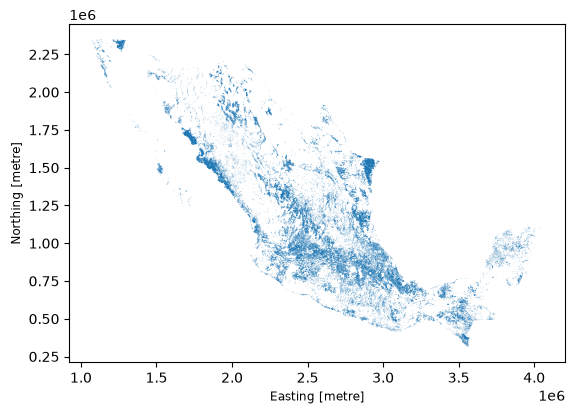

In [3]:
agro.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

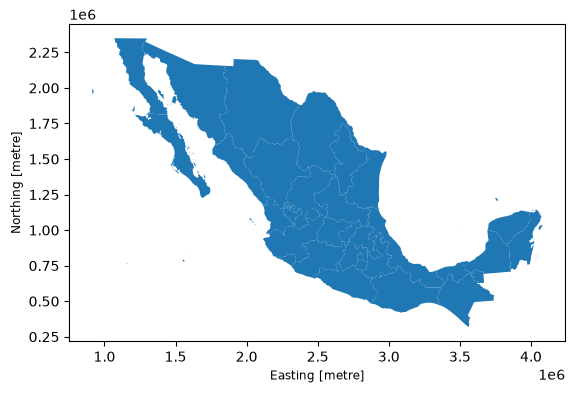

In [4]:
mexico.plot()

In [5]:
mexico.crs

<Projected CRS: EPSG:6372>
Name: Mexico ITRF2008 / LCC
Axis Info [cartesian]:
- N[north]: Northing (metre)
- E[east]: Easting (metre)
Area of Use:
- name: Mexico - onshore and offshore.
- bounds: (-122.19, 12.1, -84.64, 32.72)
Coordinate Operation:
- name: Mexico LCC
- method: Lambert Conic Conformal (2SP)
Datum: Mexico ITRF2008
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [6]:
agro.crs

<Projected CRS: PROJCS["Albers_Conic_Equal_Area",GEOGCS["GCS_GRS_1 ...>
Name: Albers_Conic_Equal_Area
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Albers Equal Area
Datum: unknown
- Ellipsoid: GRS80
- Prime Meridian: Greenwich

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

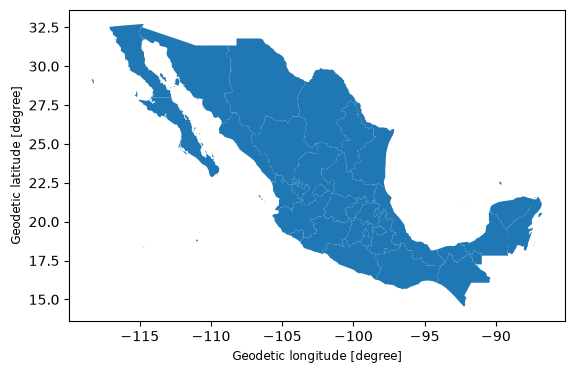

In [7]:
mexico.to_crs(crs='EPSG:4326', inplace=True)
mexico.plot()

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

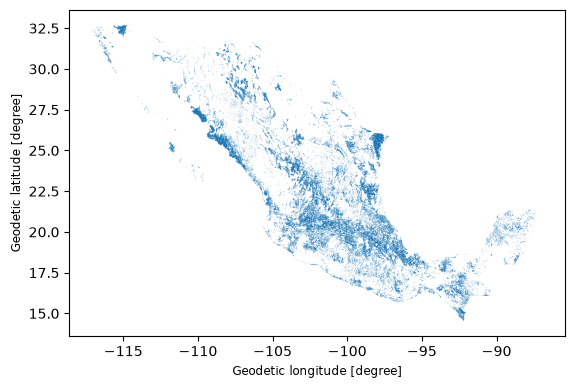

In [8]:
agro['Centro'] = agro['geometry'].centroid
agro.to_crs(crs='EPSG:4326', inplace=True)
agro.plot()

In [9]:
agroent = gpd.sjoin(mexico, agro, how="inner", predicate="contains").reset_index(drop=True)

In [10]:
agroent.drop(columns = ['index_right', 'CLAVE', 'CVEGEO'], inplace=True)

In [11]:
agroent['Centro']=agroent['Centro'].to_crs(epsg=4326)
agroent

,CVE_ENT,NOMGEO,geometry,DESCRIPCIO,Centro
0,01,Aguascalientes,"POLYGON ((-102.29739 22.45527, -102.29554 22.4...",AGRICULTURA DE RIEGO ANUAL,POINT (-102.12733 21.78127)
1,01,Aguascalientes,"POLYGON ((-102.29739 22.45527, -102.29554 22.4...",AGRICULTURA DE RIEGO ANUAL,POINT (-102.12013 21.83274)
2,01,Aguascalientes,"POLYGON ((-102.29739 22.45527, -102.29554 22.4...",AGRICULTURA DE TEMPORAL ANUAL,POINT (-102.07812 22.05563)
3,01,Aguascalientes,"POLYGON ((-102.29739 22.45527, -102.29554 22.4...",AGRICULTURA DE RIEGO ANUAL,POINT (-101.96163 22.06091)
4,01,Aguascalientes,"POLYGON ((-102.29739 22.45527, -102.29554 22.4...",AGRICULTURA DE RIEGO ANUAL Y SEMIPERMANENTE,POINT (-101.99229 22.07167)
...,...,...,...,...,...
34471,32,Zacatecas,"POLYGON ((-102.29548 25.12519, -102.26655 25.1...",AGRICULTURA DE TEMPORAL ANUAL,POINT (-102.12415 24.78334)
34472,32,Zacatecas,"POLYGON ((-102.29548 25.12519, -102.26655 25.1...",AGRICULTURA DE TEMPORAL ANUAL,POINT (-102.13454 24.79761)
34473,32,Zacatecas,"POLYGON ((-102.29548 25.12519, -102.26655 25.1...",AGRICULTURA DE RIEGO ANUAL,POINT (-102.00323 24.86572)
34474,32,Zacatecas,"POLYGON ((-102.29548 25.12519, -102.26655 25.1...",AGRICULTURA DE TEMPORAL ANUAL,POINT (-101.71235 24.74721)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

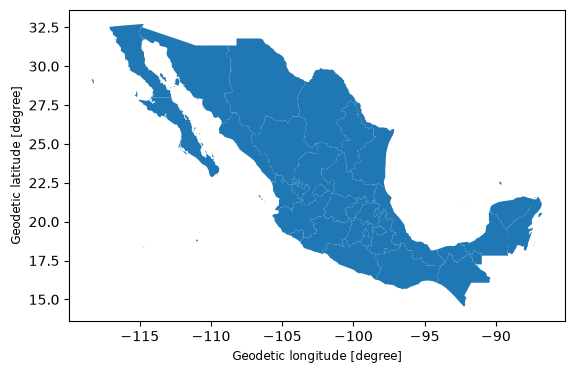

In [12]:
mexico.plot()

In [13]:
mexico

,CVEGEO,CVE_ENT,NOMGEO,geometry
0,01,01,Aguascalientes,"POLYGON ((-102.29739 22.45527, -102.29554 22.4..."
1,02,02,Baja California,"MULTIPOLYGON (((-114.11561 28.09639, -114.1152..."
2,03,03,Baja California Sur,"MULTIPOLYGON (((-109.89451 22.87476, -109.8946..."
3,04,04,Campeche,"MULTIPOLYGON (((-91.9565 20.197, -91.95636 20...."
4,05,05,Coahuila de Zaragoza,"POLYGON ((-102.31549 29.88, -102.31509 29.8799..."
5,06,06,Colima,"MULTIPOLYGON (((-114.73734 18.37206, -114.7364..."
6,07,07,Chiapas,"POLYGON ((-91.99567 17.94259, -91.99296 17.939..."
7,08,08,Chihuahua,"POLYGON ((-107.65314 31.78369, -107.65314 31.7..."
8,09,09,Ciudad de México,"POLYGON ((-99.11124 19.5615, -99.11485 19.5576..."
9,10,10,Durango,"POLYGON ((-105.96732 26.78554, -105.93919 26.7..."


In [14]:
agropoints = agroent['Centro'].to_list()
agropoints

[<POINT (-102.127 21.781)>,
 <POINT (-102.12 21.833)>,
 <POINT (-102.078 22.056)>,
 <POINT (-101.962 22.061)>,
 <POINT (-101.992 22.072)>,
 <POINT (-102.125 22.077)>,
 <POINT (-102.115 22.085)>,
 <POINT (-102.098 22.09)>,
 <POINT (-102.014 22.098)>,
 <POINT (-102.733 21.877)>,
 <POINT (-102.703 21.902)>,
 <POINT (-102.795 21.9)>,
 <POINT (-102.643 21.898)>,
 <POINT (-102.736 21.905)>,
 <POINT (-102.113 21.868)>,
 <POINT (-101.985 21.89)>,
 <POINT (-102.073 21.933)>,
 <POINT (-102 21.963)>,
 <POINT (-102.125 21.991)>,
 <POINT (-101.933 22.012)>,
 <POINT (-101.986 22.028)>,
 <POINT (-102.062 22.049)>,
 <POINT (-102.337 21.799)>,
 <POINT (-102.268 21.803)>,
 <POINT (-102.271 21.814)>,
 <POINT (-102.271 21.838)>,
 <POINT (-102.155 21.988)>,
 <POINT (-102.201 21.989)>,
 <POINT (-102.218 22.021)>,
 <POINT (-102.344 22.051)>,
 <POINT (-102.221 22.059)>,
 <POINT (-102.271 22.063)>,
 <POINT (-102.731 21.918)>,
 <POINT (-102.716 21.926)>,
 <POINT (-102.742 21.939)>,
 <POINT (-102.735 21.947)>,
 

In [16]:
agropoints

[<POINT (-102.127 21.781)>,
 <POINT (-102.12 21.833)>,
 <POINT (-102.078 22.056)>,
 <POINT (-101.962 22.061)>,
 <POINT (-101.992 22.072)>,
 <POINT (-102.125 22.077)>,
 <POINT (-102.115 22.085)>,
 <POINT (-102.098 22.09)>,
 <POINT (-102.014 22.098)>,
 <POINT (-102.733 21.877)>,
 <POINT (-102.703 21.902)>,
 <POINT (-102.795 21.9)>,
 <POINT (-102.643 21.898)>,
 <POINT (-102.736 21.905)>,
 <POINT (-102.113 21.868)>,
 <POINT (-101.985 21.89)>,
 <POINT (-102.073 21.933)>,
 <POINT (-102 21.963)>,
 <POINT (-102.125 21.991)>,
 <POINT (-101.933 22.012)>,
 <POINT (-101.986 22.028)>,
 <POINT (-102.062 22.049)>,
 <POINT (-102.337 21.799)>,
 <POINT (-102.268 21.803)>,
 <POINT (-102.271 21.814)>,
 <POINT (-102.271 21.838)>,
 <POINT (-102.155 21.988)>,
 <POINT (-102.201 21.989)>,
 <POINT (-102.218 22.021)>,
 <POINT (-102.344 22.051)>,
 <POINT (-102.221 22.059)>,
 <POINT (-102.271 22.063)>,
 <POINT (-102.731 21.918)>,
 <POINT (-102.716 21.926)>,
 <POINT (-102.742 21.939)>,
 <POINT (-102.735 21.947)>,
 

In [19]:
import datetime

start_date = "2010-01-01"
end_date = "2026-10-19" 
period = 18


m0 = datetime.date(2010,1,1)
mf = datetime.date(2026, 10, 19)
periods = []
q = m0 + datetime.timedelta(days=18)

while m0 < mf:
    m = m0 + datetime.timedelta(days=18)
    periods.append([m0, m])
    m0 = m + datetime.timedelta(days=1)

ml = periods[-1][0]
periods[-1] = [ml, mf]


In [23]:
periods[0][0].strftime("%Y-%m-%d")

'2010-01-01'

In [36]:
import requests
from yarl import URL
API_KEY = "12f964090e554767b8a12335261310"

BASE_URL= URL("http://api.weatherapi.com/v1")


def set_query(place, period):
    lon, lat = place[0], place[1]
    start, last = period[0], period[1]
    query = {"key": API_KEY,
    "q":f"{lat},{lon}",
    "dt":f"{start.strftime("%Y-%m-%d")}",
    "end_dt":f"{last.strftime("%Y-%m-%d")}",
    "solar":"yes",
    "et0":"yes"
    }
    return query


agrocoords = [p.coords[0] for p in agropoints]


test = set_query(agrocoords[0], periods[0])


test

{'key': '12f964090e554767b8a12335261310',
 'q': '21.781267898283854,-102.12733106760648',
 'dt': '2010-01-01',
 'end_dt': '2010-01-19',
 'solar': 'yes',
 'et0': 'yes'}

In [37]:
url = BASE_URL / "history.json"
url = url.with_query(test)
response = requests.get(url)
response.raise_for_status()

g = response.json()


In [42]:

import json

with open(f"data_{1}.json", "w") as doc:
    json.dump(g, doc)

In [46]:
len(agropoints) * len(periods) // 100000

111

In [59]:
u = 0

url = BASE_URL / "history.json"
for dt in periods:
    for p in agrocoords:
        query = set_query(p, dt)
        print(p, dt)
        url = url.with_query(query)
        response = requests.get(url)
        response.raise_for_status()
        file = response.json()
        with open(f"data_{u}.json", "w") as doc:
            json.dump(file, doc)
        u+=1

(-102.12733106760648, 21.781267898283854) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.12012915878556, 21.83274016112649) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.07811700479934, 22.055628728016917) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-101.96163145158982, 22.06091340425009) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-101.99229325179549, 22.071666160108308) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.12464468052222, 22.077387008833174) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.11534150933082, 22.085096412544715) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.09803545500823, 22.090465123598385) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.01366129477346, 22.098159718513898) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.73274446856874, 21.87734490861597) [datetime.date(2010, 1, 1), datetime.date(2010, 1, 19)]
(-102.7030390462471, 21

HTTPError: 408 Client Error: Request Timeout for url: http://api.weatherapi.com/v1/history.json?key=12f964090e554767b8a12335261310&q=19.960413521039232,-102.05146759340568&dt=2010-01-01&end_dt=2010-01-19&solar=yes&et0=yes